# The echelle spectrograph

Planet hunters measure stellar radial velocities to a metre per second,
a Doppler shift of $3\cdot10^{-9}$, from thousands of absorption lines
spread over the whole visible spectrum. That needs a resolving power
$R = \lambda/\Delta\lambda$ of about $10^5$ and a wide band on one
detector at the same time. A first order grating cannot do both: a
spectrum of $10^5$ resolution elements is metres long. The echelle
(French for ladder) solves it with a coarse grating of steep, staircase
like grooves used in very high orders, $m \approx 90$ to $160$. Each
order covers only a few nanometres, the *free spectral range*
$\lambda/m$, and a second, weak disperser at right angles stacks the
orders on top of each other: the two-dimensional *echellogram*.

This notebook uses `pyoptics.echelle` for:

1. the grating equation in high orders, the Littrow configuration and
   the dispersion $2\tan\theta_B/\lambda$, the same in every order,
2. the blaze: the facet diffraction pattern that decides which orders
   are bright, checked by the FFT of the staircase wavefront against
   $\mathrm{sinc}^2(m - m_B)$,
3. the free spectral range and why the orders must be separated,
4. cross-dispersion with a grating or a prism, and the echellogram of a
   sunlike spectrum with its Fraunhofer lines,
5. the resolving power: the diffraction limit $R = mN$ and the slit
   limited $R = 2\tan\theta_B f_\mathrm{coll}/s$, and the $R\phi$ product
   that makes spectrographs for large telescopes large,
6. extracting an order and dividing out the blaze.

The instrument is modelled on HARPS (ESO 3.6 m telescope): an R4
echelle (blaze angle $\arctan 4 = 76°$) with 31.6 grooves/mm, orders 89 to
161 for 380 to 690 nm. Scalar diffraction is used throughout; the
polarization dependence of real echelle efficiencies is left out.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import echelle as ec
from pyoptics import glasses
from pyoptics import sketch

t_start = time.time()

## The setup

Light from the slit is collimated, diffracted by the echelle, dispersed
again at right angles by the cross-disperser and imaged by the camera
onto the detector. The echelle is used near Littrow: the light leaves
the grating almost back along the way it came in (in practice tilted by
a small angle $\gamma$ out of the drawing plane, or slightly in plane, to
separate the beams). The grooves are right-angle steps; the light falls
on the narrow facets that face it, of width $b = d\cos\theta_B$, which are
$d\sin\theta_B$ apart along the beam.

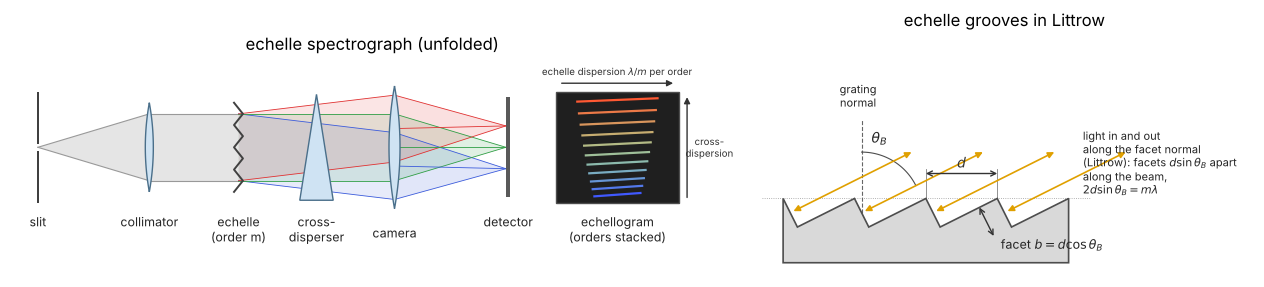

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[1.45, 1]))
sketch.echelle_layout(axs[0], title="echelle spectrograph (unfolded)")
sketch.echelle_layout(axs[1], kind="grooves", title="echelle grooves in Littrow")
plt.tight_layout()
plt.show()

## 1. The grating equation in high orders

With the angle of incidence $\alpha$, the diffraction angle $\beta$ (both
from the grating normal) and the off-plane angle $\gamma$ the grating
equation reads

$$m\lambda = d\cos\gamma\,(\sin\alpha + \sin\beta).$$

In Littrow ($\alpha = \beta = \theta_B$, $\gamma = 0$) the order on the blaze is
$m_B = 2d\sin\theta_B/\lambda$, and the angular dispersion

$$\frac{d\beta}{d\lambda} = \frac{m}{d\cos\beta} = \frac{2\tan\theta_B}{\lambda}$$

does not depend on the groove spacing or the order at all, only on the
blaze angle: an R4 echelle disperses four times more than a grating at
45° in any order. The coarse grooves are what puts the wavelengths into
high orders, where each order is short.

In [3]:
E = ec.Echelle(31.6, np.arctan(4.0))
f_cam = 500.0                                    # camera focal length (mm)
print("groove spacing d = %.0f nm, blaze angle %.2f deg, facet b = %.0f nm"
      % (E.d, np.degrees(E.blaze), E.facet))
orders = E.orders(380.0, 690.0)
print("orders %d to %d cover 380 to 690 nm (%d orders)" % (orders[0], orders[-1], len(orders)))
print()
print("%5s %10s %10s %12s %14s %16s" % ("m", "lambda_B", "FSR", "length (mm)", "2f tan/m (mm)",
                                        "dbeta/dlam (rad/um)"))
for m in (161, 140, 123, 105, 89):
    lam = E.blaze_wavelength(m)
    lo, hi = E.fsr_limits(m)
    x_lo = f_cam*np.tan(E.beta(m, lo) - E.blaze)
    x_hi = f_cam*np.tan(E.beta(m, hi) - E.blaze)
    print("%5d %10.2f %10.3f %12.2f %14.2f %16.2f"
          % (m, lam, hi - lo, x_hi - x_lo, 2*f_cam*np.tan(E.blaze)/m, 1e3*E.dispersion(m, lam)))
first = 1e3/(1e6/600.0*np.cos(np.arcsin(500.0/(1e6/600.0))))
print()
print("for comparison: a 600 grooves/mm grating in first order at 500 nm: %.2f rad/um" % first)

groove spacing d = 31646 nm, blaze angle 75.96 deg, facet b = 7675 nm
orders 162 to 89 cover 380 to 690 nm (74 orders)

    m   lambda_B        FSR  length (mm)  2f tan/m (mm) dbeta/dlam (rad/um)
  161     381.38      2.369        24.99          24.84            20.98
  140     438.58      3.133        28.79          28.57            18.24
  123     499.20      4.059        32.84          32.52            16.03
  105     584.78      5.569        38.62          38.10            13.68
   89     689.90      7.752        45.82          44.94            11.60

for comparison: a 600 grooves/mm grating in first order at 500 nm: 0.63 rad/um


Each order is a strip of about $\lambda/m \approx 4$ nm, and its length
on the detector, $2f\tan\theta_B/m$, grows towards the red (the small
excess over the formula comes from the tangent of the camera). The
dispersion in the middle of each order is $2\tan\theta_B/\lambda$, 16 rad/µm
at 500 nm, against 0.6 rad/µm for a typical first order grating.

## 2. The blaze

Which orders are bright is decided by diffraction at a single facet. In
the scalar theory the facet of width $b$ radiates the pattern

$$\eta = \mathrm{sinc}^2\nu,\qquad \nu = \frac{b\cos\gamma}{\lambda}\left[\sin(\alpha-\theta_B) + \sin(\beta-\theta_B)\right],$$

with $\mathrm{sinc}\,x = \sin(\pi x)/(\pi x)$, centred on the specular reflection
from the facet. In Littrow $\nu = m - m_B$ to first order in $\beta -
\theta_B$: the light of a wavelength goes into the orders around the
continuous $m_B(\lambda)$ in the shares $\mathrm{sinc}^2(m - m_B)$, which add up to 1.
On the blaze wavelength of an order ($m_B$ an integer) it all goes into
that order; half way between two blaze wavelengths it is split evenly
between the two neighbours, $4/\pi^2 = 40.5$ % each.

A direct check: in Littrow the facets face the beam, so the reflected
wavefront is a staircase of steps $b$ wide, each delayed by $2d\sin\theta_B =
m_B\lambda$ against the next. Its far field by FFT
(`staircase_far_field()`) gives the order shares without any formula.

In [4]:
m0 = E.central_order(500.0)
ms = np.arange(m0 - 3, m0 + 4)
print("%9s" % "lambda" + "".join("%9d" % m for m in ms) + "   sum")
for lam in (E.blaze_wavelength(m0), E.blaze_wavelength(m0) + 1.0, E.blaze_wavelength(m0 + 0.5)):
    fft = ec.order_efficiencies(E, lam, ms, n_facets=1000)
    ref = np.sinc(ms - E.littrow_order(lam))**2
    print("%9.3f" % lam + "".join("%9.4f" % v for v in fft) + "   %.4f   staircase FFT" % fft.sum())
    print("%9s" % "" + "".join("%9.4f" % v for v in ref) + "   %.4f   sinc^2(m - m_B)" % ref.sum())

   lambda      120      121      122      123      124      125      126   sum
  499.199   0.0000   0.0000   0.0001   0.9998   0.0001   0.0000   0.0000   1.0000   staircase FFT
            0.0000   0.0000   0.0000   1.0000   0.0000   0.0000   0.0000   1.0000   sinc^2(m - m_B)
  500.199   0.0072   0.0167   0.0875   0.8168   0.0324   0.0104   0.0054   0.9764   staircase FFT
            0.0065   0.0160   0.0868   0.8162   0.0318   0.0098   0.0047   0.9718   sinc^2(m - m_B)
  497.178   0.0097   0.0176   0.0463   0.4066   0.4066   0.0463   0.0176   0.9508   staircase FFT
            0.0083   0.0162   0.0450   0.4053   0.4053   0.0450   0.0162   0.9413   sinc^2(m - m_B)


The staircase agrees with $\mathrm{sinc}^2(m - m_B)$ to the sampling of the
FFT (about $10^{-3}$); the seven orders shown hold 95 to 98 % of the
light, the rest goes into the higher orders. The far field itself, with the orders under the facet envelope:

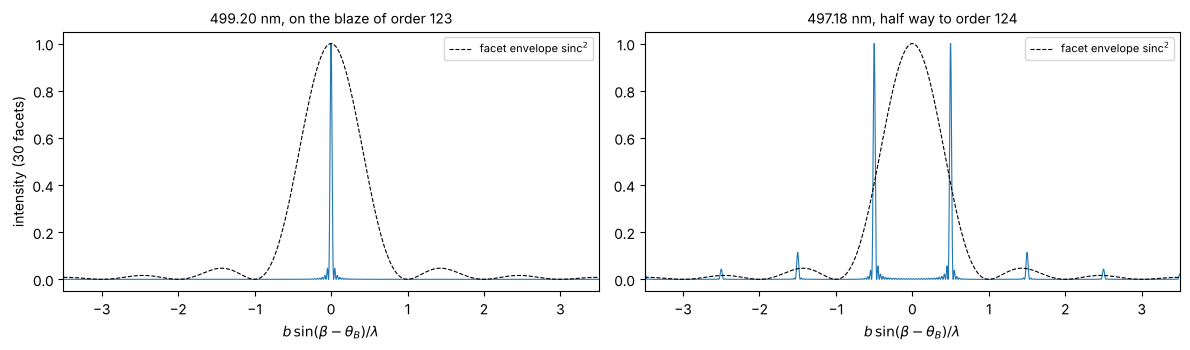

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, lam, txt in ((axs[0], E.blaze_wavelength(m0), "on the blaze of order %d" % m0),
                     (axs[1], E.blaze_wavelength(m0 + 0.5), "half way to order %d" % (m0 + 1))):
    delta, I = ec.staircase_far_field(E, lam, n_facets=30, samples=16, pad=16)
    u = delta*E.facet/lam
    ax.plot(u, I/I.max(), lw=0.8)
    ax.plot(u, np.sinc(u)**2, "k--", lw=0.8, label="facet envelope sinc$^2$")
    ax.set_xlim(-3.5, 3.5)
    ax.set_xlabel(r"$b\,\sin(\beta - \theta_B)/\lambda$")
    ax.set_title("%.2f nm, %s" % (lam, txt), fontsize=10)
    ax.legend(fontsize=8)
axs[0].set_ylabel("intensity (30 facets)")
plt.tight_layout()
plt.show()

With the exact grating equation instead of its first order form, the
blaze function of each order against the wavelength (the incidence fixed
at $\theta_B$). The exact blaze curves are slightly asymmetric: the facet
envelope is a function of $\sin(\beta - \theta_B)$, the orders are equally
spaced in $\sin\beta$.

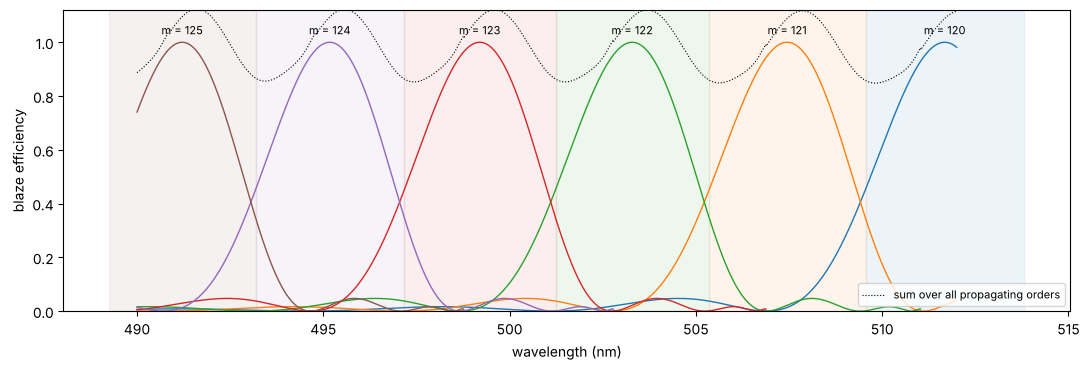

exact blaze function vs sinc^2(m - m_B) in order 123:
  497.70 nm: 0.6493  0.6222
  498.70 nm: 0.9524  0.9510
  499.70 nm: 0.9496  0.9512
  500.70 nm: 0.5928  0.6259


In [6]:
fig, ax = plt.subplots(figsize=(11, 3.8))
lam = np.linspace(490, 512, 4000)
for m in range(m0 - 3, m0 + 3):
    eff = E.efficiency(m, lam)
    line, = ax.plot(lam, eff, lw=1)
    lo, hi = E.fsr_limits(m)
    ax.axvspan(lo, hi, color=line.get_color(), alpha=0.08)
    ax.text(E.blaze_wavelength(m), 1.03, "m = %d" % m, ha="center", fontsize=8)
ax.plot(lam, np.nansum([E.efficiency(m, lam) for m in range(m0 - 8, m0 + 9)], axis=0), "k:",
        lw=0.8, label="sum over all propagating orders")
ax.set_ylim(0, 1.12)
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("blaze efficiency")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()
lam = E.blaze_wavelength(m0) + np.array([-1.5, -0.5, 0.5, 1.5])
print("exact blaze function vs sinc^2(m - m_B) in order %d:" % m0)
for l_ in lam:
    print("  %.2f nm: %.4f  %.4f" % (l_, E.efficiency(m0, l_), np.sinc(m0 - E.littrow_order(l_))**2))

Inside the free spectral range of an order (shaded) its efficiency stays
above 40 %; at the edges the light is shared with the neighbour. The
exact and first order blaze functions agree to a few tenths of a percent
near the peak and to about 3 % at the edges of the free spectral range. The sum over orders is not exactly 1 in the
exact form: the orders on the far side of the grating normal no longer
propagate ($\beta > 90°$ beyond $m_B + 3$), and the scalar theory does not
conserve energy at such steep angles. Real echelles in Littrow reach
60 to 70 % peak efficiency.

## 3. The free spectral range

Every wavelength appears in several orders at once, at the same angle
$\beta$ as the wavelengths $\lambda\,m/(m\pm1)$ of the neighbouring orders. Along
the echelle dispersion alone the orders lie on top of each other, so
the light must be sorted by a second disperser. Which wavelengths share
the direction of the 500 nm light of the central order:

In [7]:
b500 = E.beta(m0, 500.0)
for m in range(m0 - 3, m0 + 4):
    print("order %3d: %8.3f nm (blaze efficiency %.3f)" % (m, E.wavelength(m, b500),
                                                            E.efficiency(m, E.wavelength(m, b500))))

order 120:  512.500 nm (blaze efficiency 0.878)
order 121:  508.264 nm (blaze efficiency 0.876)
order 122:  504.098 nm (blaze efficiency 0.874)
order 123:  500.000 nm (blaze efficiency 0.872)
order 124:  495.968 nm (blaze efficiency 0.870)
order 125:  492.000 nm (blaze efficiency 0.868)
order 126:  488.095 nm (blaze efficiency 0.866)


## 4. Cross-dispersion and the echellogram

The cross-disperser deflects by an angle $\phi(\lambda)$ perpendicular to
the echelle dispersion. Adjacent orders differ by $\lambda/m$ in wavelength
at the same $\beta$, so they are separated on the detector by

$$\Delta y = f\,\frac{d\phi}{d\lambda}\,\frac{\lambda}{m} \propto \frac{d\phi}{d\lambda}\,\lambda^2 .$$

A grating ($d\phi/d\lambda \approx$ const) crowds the blue orders, $\Delta y \propto
\lambda^2$; a prism, whose dispersion grows towards the blue roughly as
$\lambda^{-3}$, spaces them the other way round and somewhat more evenly.
Here a 200 grooves/mm grating in first order and a 60° prism of N-F2 at
minimum deviation, both with the 500 mm camera:

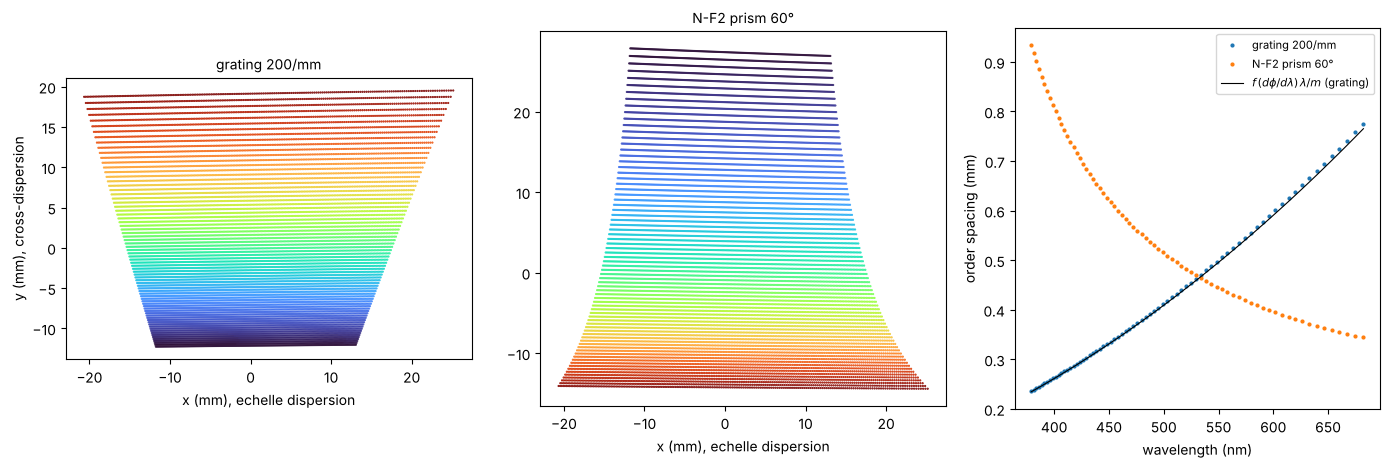

grating: spacing 0.236 to 0.775 mm (ratio 3.28, (lambda ratio)^2 = 3.24)
prism:   spacing 0.933 to 0.344 mm (ratio 0.37)
max. deviation of the grating spacing from the formula: 1.3 %


In [8]:
cd_grating = ec.GratingCrossDisperser(200.0)
cd_prism = ec.PrismCrossDisperser(glasses.get("N-F2"), np.radians(60.0))
fig, axs = plt.subplots(1, 3, figsize=(14, 4.6), gridspec_kw=dict(width_ratios=[1, 1, 0.9]))
spacing = {}
for ax, cd, name in ((axs[0], cd_grating, "grating 200/mm"), (axs[1], cd_prism, "N-F2 prism 60°")):
    ys = []
    for m in orders:
        lo, hi = E.fsr_limits(m)
        lam = np.linspace(lo, hi, 200)
        x, y = ec.order_position(E, cd, m, lam, f_cam)
        ax.scatter(x, y, c=lam, cmap="turbo", vmin=380, vmax=690, s=0.3)
        ys.append(ec.order_position(E, cd, m, E.blaze_wavelength(m), f_cam)[1])
    spacing[name] = np.abs(np.diff(ys))
    ax.set_aspect("equal")
    ax.set_xlabel("x (mm), echelle dispersion")
    ax.set_title(name, fontsize=10)
axs[0].set_ylabel("y (mm), cross-dispersion")
lam_mid = E.blaze_wavelength(orders[:-1])
for name, s in spacing.items():
    axs[2].plot(lam_mid, s, ".", ms=4, label=name)
dy_ana = f_cam*cd_grating.dispersion(lam_mid)*lam_mid/orders[:-1]
axs[2].plot(lam_mid, dy_ana, "k-", lw=0.8, label=r"$f\,(d\phi/d\lambda)\,\lambda/m$ (grating)")
axs[2].set_xlabel("wavelength (nm)")
axs[2].set_ylabel("order spacing (mm)")
axs[2].legend(fontsize=8)
plt.tight_layout()
plt.show()
g = spacing["grating 200/mm"]
p = spacing["N-F2 prism 60°"]
print("grating: spacing %.3f to %.3f mm (ratio %.2f, (lambda ratio)^2 = %.2f)"
      % (g[0], g[-1], g[-1]/g[0], (lam_mid[-1]/lam_mid[0])**2))
print("prism:   spacing %.3f to %.3f mm (ratio %.2f)" % (p[0], p[-1], p[-1]/p[0]))
print("max. deviation of the grating spacing from the formula: %.1f %%"
      % (100*np.max(np.abs(g/dy_ana - 1))))

With the grating the spacing grows from 0.24 mm in the blue to 0.78 mm
in the red, as $\lambda^2$ (to 1.3 %: the formula takes the dispersion at the
blaze wavelength of one order). The prism reverses the trend, from
0.93 mm in the blue to 0.34 mm in the red, a factor 2.7 instead of 3.3.
With a slit image of 0.15 mm both leave room between the orders for the
sky or a calibration lamp, as HARPS does with its second fibre.

Now the image of a sunlike spectrum: a 5800 K blackbody with the
strongest Fraunhofer lines (Ca II H and K, the Balmer lines, the Mg b
triplet, the Na D doublet), each order weighted by its blaze function,
on a 4k × 4k detector with 15 µm pixels.

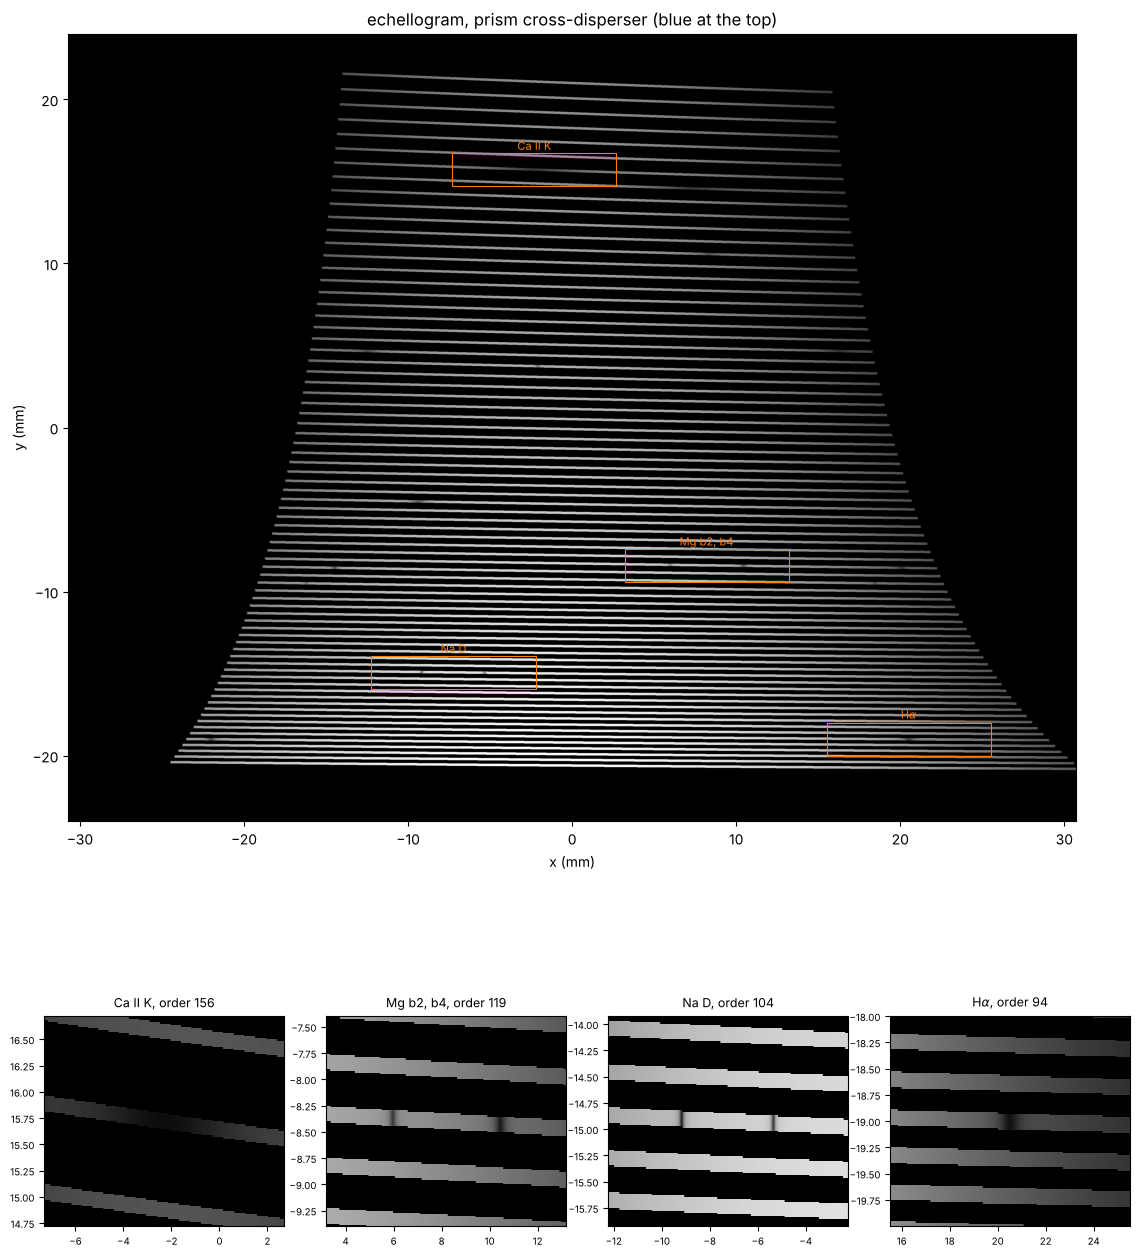

In [9]:
pixel = 0.015
shape = (4096, 4096)
# centre the echellogram: the wavelength half way in cross-dispersion angle
lg = np.linspace(380, 690, 3001)
ang = cd_prism.angle(lg)
lam_ref = lg[np.argmin(np.abs(ang - (ang[0] + ang[-1])/2))]
img, ext = ec.echellogram(ec.solar_like_spectrum, E, cd_prism, f_cam, orders, pixel, shape,
                          slit_height=0.15, n_samples=40000, wavelength_ref=lam_ref)
fig = plt.figure(figsize=(12, 14))
ax = fig.add_axes([0.08, 0.25, 0.84, 0.72])
ax.imshow(np.sqrt(np.clip(img, 0, None)), extent=ext, origin="lower", cmap="gray")
ax.set_xlabel("x (mm)")
ax.set_ylabel("y (mm)")
ax.set_ylim(-24, 24)
ax.set_title("echellogram, prism cross-disperser (blue at the top)")
zooms = (("Ca II K", 393.37), ("Mg b2, b4", 517.0), ("Na D", 589.3), (r"H$\alpha$", 656.28))
for k, (name, lc) in enumerate(zooms):
    m = E.central_order(lc)
    x, y = ec.order_position(E, cd_prism, m, lc, f_cam, wavelength_ref=lam_ref)
    ax.add_patch(plt.Rectangle((x - 5, y - 1), 10, 2, fill=False, ec="C1", lw=0.8))
    ax.text(x, y + 1.2, name, color="C1", fontsize=8, ha="center")
    sub = fig.add_axes([0.06 + k*0.235, 0.04, 0.2, 0.15])
    sub.imshow(img, extent=ext, origin="lower", cmap="gray", interpolation="nearest", aspect="auto")
    sub.set_xlim(x - 5, x + 5)
    sub.set_ylim(y - 1, y + 1)
    sub.set_title("%s, order %d" % (name, m), fontsize=9)
    sub.tick_params(labelsize=7)
plt.show()

The orders run from the blue at the top (short and close together, the
prism disperses most there) to the red at the bottom. Each order is
brightest in the middle (the blaze) and fades towards both ends, where
the same wavelengths appear again at the opposite end of the next order.
The overall brightness follows the blackbody and the deep, broad H and K
lines of ionized calcium cut the blue orders. The zooms show Ca II K,
two lines of the Mg b triplet, the Na D doublet 0.6 nm apart (4 mm or 270 pixels at this
dispersion) and H$\alpha$.

## 5. Resolving power

### The diffraction limit

A grating of $N$ illuminated grooves resolves $\lambda/\Delta\lambda = mN$
(Rayleigh); the FWHM of a line corresponds to $mN/0.886$. The width of
the order peaks in the staircase far field:

In [10]:
lam = E.blaze_wavelength(m0)
print("%6s %14s %14s" % ("N", "R from FWHM", "m N/0.886"))
for N in (20, 50, 100, 300):
    delta, I = ec.staircase_far_field(E, lam, n_facets=N, samples=8, pad=64)
    near = np.abs(delta) < 2*lam/(N*E.facet)
    w = ec.fwhm(delta[near], I[near])
    print("%6d %14.0f %14.0f" % (N, lam/(w/E.dispersion(m0, lam)), m0*N/0.886))
W = 200e6                                       # collimated beam 200 mm (nm)
N = W/E.facet
print()
print("a 200 mm beam covers N = %.0f grooves: R = m N = %.2g (= 2 W tan(theta_B)/lambda = %.2g)"
      % (N, m0*N, 2*W*np.tan(E.blaze)/lam))

     N    R from FWHM      m N/0.886
    20           2777           2777
    50           6942           6941
   100          13884          13883
   300          41652          41648

a 200 mm beam covers N = 26058 grooves: R = m N = 3.2e+06 (= 2 W tan(theta_B)/lambda = 3.2e+06)


Diffraction would allow millions. In practice the image of the slit (or
of the fibre) is much wider than the diffraction pattern.

### The slit

A slit of width $s$ in the focus of the collimator ($f_\mathrm{coll}$) sends
light into the angles $\pm s/(2f_\mathrm{coll})$; in Littrow the echelle maps
them one to one onto $\beta$, so the line has the angular width
$s/f_\mathrm{coll}$ and

$$R = \frac{2\tan\theta_B\,f_\mathrm{coll}}{s}.$$

The instrument profile is the slit image convolved with the diffraction
pattern of the beam (`instrument_profile()`). Its FWHM against the slit
width, for the 200 mm beam and $f_\mathrm{coll} = 1500$ mm:

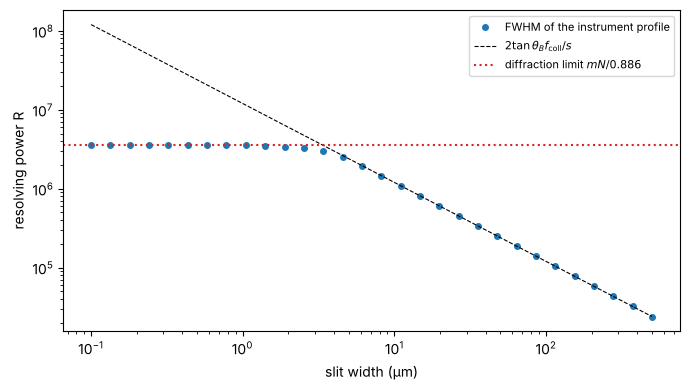

slit  50 um: R = 239871 (formula 240000)


slit 100 um: R = 119983 (formula 120000)


slit 200 um: R = 59998 (formula 60000)


In [11]:
f_coll = 1500.0
delta = np.linspace(-2e-4, 2e-4, 400001)
slits = np.geomspace(1e-4, 0.5, 30)             # mm
R_num = []
for s in slits:
    prof = ec.instrument_profile(delta, s/f_coll, W, lam)
    R_num.append(lam/(ec.fwhm(delta, prof)/E.dispersion(m0, lam)))
R_num = np.array(R_num)
R_diff = 2*W*np.tan(E.blaze)/lam/0.886
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(slits*1e3, R_num, "o", ms=4, label="FWHM of the instrument profile")
ax.loglog(slits*1e3, ec.slit_resolving_power(E.blaze, f_coll, slits), "k--", lw=0.8,
          label=r"$2\tan\theta_B f_\mathrm{coll}/s$")
ax.axhline(R_diff, color="C3", ls=":", label="diffraction limit $mN/0.886$")
ax.set_xlabel("slit width (µm)")
ax.set_ylabel("resolving power R")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
for s in (0.05, 0.1, 0.2):
    k = np.argmin(np.abs(slits - s))
    prof = ec.instrument_profile(delta, s/f_coll, W, lam)
    R = lam/(ec.fwhm(delta, prof)/E.dispersion(m0, lam))
    print("slit %3.0f um: R = %.0f (formula %.0f)" % (s*1e3, R, ec.slit_resolving_power(E.blaze, f_coll, s)))

For any practical slit the formula holds to within 0.1 %; only below a
few micrometres (the diffraction limited spot of the collimator) does
the diffraction pattern take over.

What a resolving power means for the spectrum: two lines 6 pm apart at
589 nm (a Doppler shift of 3 km/s) seen through slits of 0.3, 0.1 and
0.05 mm:

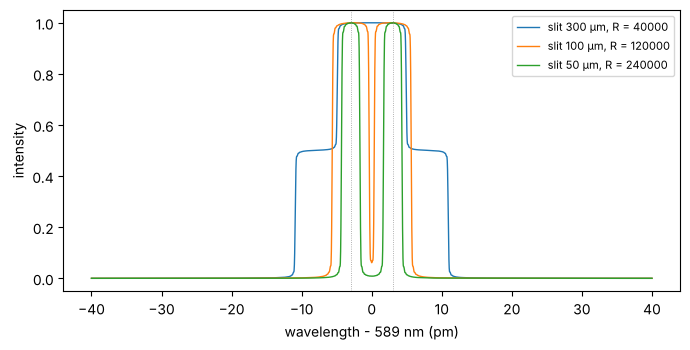

needed: R about lambda/dl = 98167


In [12]:
fig, ax = plt.subplots(figsize=(7, 3.6))
dl = 0.006
grid = np.linspace(-0.04, 0.04, 4001)                       # nm around 589
lam0 = 589.0
mD = E.central_order(lam0)
for s in (0.3, 0.1, 0.05):
    d_ang = grid*E.dispersion(mD, lam0)
    prof = ec.instrument_profile(d_ang, s/f_coll, W, lam0)
    shift = int(round(dl/(grid[1] - grid[0])/2))
    spec = np.roll(prof, -shift) + np.roll(prof, shift)
    R = ec.slit_resolving_power(E.blaze, f_coll, s)
    ax.plot(grid*1e3, spec/spec.max(), lw=1, label="slit %.0f µm, R = %.0f" % (s*1e3, R))
for x in (-dl/2, dl/2):
    ax.axvline(x*1e3, color="0.6", lw=0.6, ls=":")
ax.set_xlabel("wavelength - 589 nm (pm)")
ax.set_ylabel("intensity")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("needed: R about lambda/dl = %.0f" % (lam0/dl))

The slit image is a top hat, so the lines keep flat tops: through the
300 µm slit ($R = 40\,000$) the doublet merges into one broad line, at
$R = 120\,000$, a little above the $\lambda/\Delta\lambda \approx 98\,000$ it
needs, the two lines are separated by a deep dip, and at $R = 240\,000$
they are fully apart.

### The $R\phi$ product

On the sky the slit has the angular width $\phi = s/(f_\mathrm{tel})$, and the
collimator must accept the telescope's focal ratio,
$f_\mathrm{coll}/D_\mathrm{coll} = f_\mathrm{tel}/D_\mathrm{tel}$. Together

$$R\,\phi = 2\tan\theta_B\,\frac{D_\mathrm{coll}}{D_\mathrm{tel}}.$$

For a given seeing disk (the slit must pass about 1″ of starlight) the
resolving power only grows with the size of the echelle against the
telescope: on a larger telescope the same resolving power needs a
proportionally larger echelle.

In [13]:
phi = np.radians(1/3600)
print("%22s %14s %16s" % ("", "R at 1 arcsec", "D_coll for R=1e5"))
for name, D_tel, D_coll in (("3.6 m, 200 mm beam", 3.6, 0.2), ("8 m, 200 mm beam", 8.2, 0.2),
                            ("39 m, 200 mm beam", 39.0, 0.2)):
    R = ec.slit_resolving_power(E.blaze, D_coll=D_coll, D_tel=D_tel, phi=phi)
    print("%22s %14.0f %14.2f m" % (name, R, 1e5*phi*D_tel/(2*np.tan(E.blaze))))

                        R at 1 arcsec D_coll for R=1e5
    3.6 m, 200 mm beam          91673           0.22 m
      8 m, 200 mm beam          40247           0.50 m
     39 m, 200 mm beam           8462           2.36 m


HARPS (a 208 mm beam on the 3.6 m) reaches $R = 115\,000$ with its 1″
fibres, a little more than the formula because the image of a round fibre
has a smaller FWHM than a slit of the same width; on an 8 m telescope the same echelle gives only 40 000, and
an extremely large telescope would need a beam of 2.4 m. Real
instruments shrink $\phi$ instead: ESPRESSO and the planned ELT
spectrographs slice the image of the star into several narrow strips
(image slicers, pupil slicers) and use mosaics of echelles.

## 6. Extracting a spectrum

To measure the spectrum, each order is summed across its width along
its trace, the pixel positions converted to wavelengths through the
grating equation, and the blaze function divided out (in practice with
a flat field lamp). The Na D order of the echellogram above, summed over
13 pixel rows:

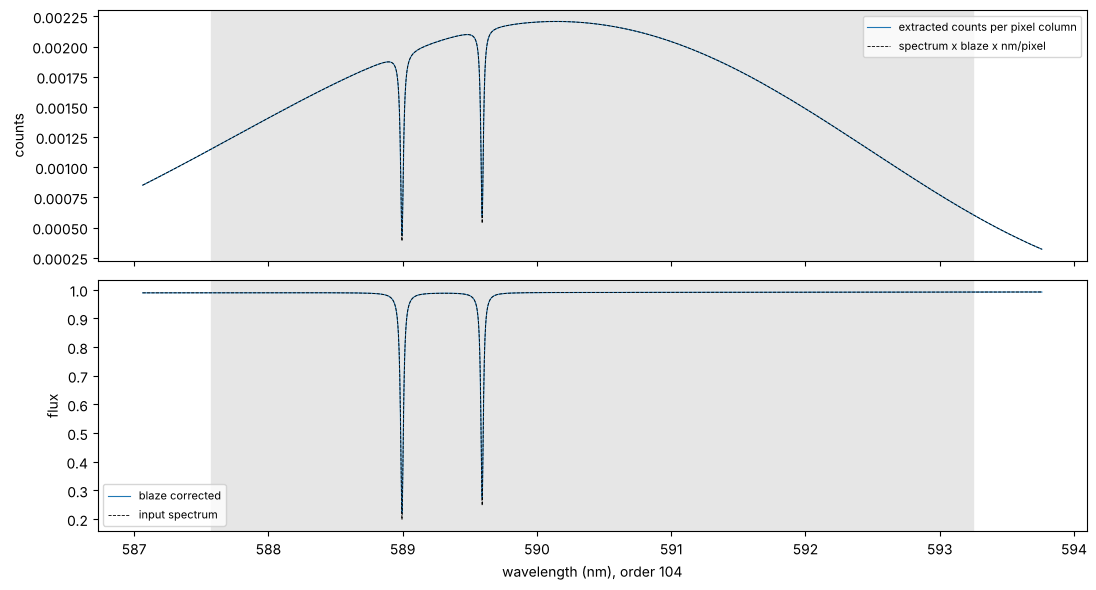

order 104: 587.06 to 593.76 nm on 3085 pixel columns
blaze corrected continuum vs input inside the FSR: rms 0.01 %


In [14]:
m = E.central_order(589.3)
lo, hi = E.fsr_limits(m)
pad = 0.09*(hi - lo)                            # inside the rendered overlap of 10 %
lam_ext = np.linspace(lo - pad, hi + pad, 20000)
x, y = ec.order_position(E, cd_prism, m, lam_ext, f_cam, wavelength_ref=lam_ref)
fx = (x - ext[0])/pixel - 0.5
cols = np.arange(int(np.ceil(fx[0])), int(np.floor(fx[-1])) + 1)
rows = np.floor((np.interp(cols, fx, y) - ext[2])/pixel).astype(int)
half = int(round(0.15/pixel))//2 + 1
counts = np.array([img[j - half:j + half + 1, i].sum() for i, j in zip(cols, rows)])
x_c = ext[0] + (cols + 0.5)*pixel
lam_c = E.wavelength(m, E.blaze + np.arctan(x_c/f_cam))
blaze = E.efficiency(m, lam_c)
dlam = np.gradient(lam_c)
truth = ec.solar_like_spectrum(lam_c)
fig, axs = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axs[0].plot(lam_c, counts, lw=0.8, label="extracted counts per pixel column")
axs[0].plot(lam_c, truth*blaze*dlam, "k--", lw=0.6, label="spectrum x blaze x nm/pixel")
axs[0].legend(fontsize=8)
axs[0].set_ylabel("counts")
corr = counts/(blaze*dlam)
axs[1].plot(lam_c, corr, lw=0.8, label="blaze corrected")
axs[1].plot(lam_c, truth, "k--", lw=0.6, label="input spectrum")
for a in axs:
    a.axvspan(lo, hi, color="0.9", zorder=0)
axs[1].set_xlabel("wavelength (nm), order %d" % m)
axs[1].set_ylabel("flux")
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
inside = (lam_c > lo) & (lam_c < hi) & (np.abs(lam_c - 589.0) > 0.3) & (np.abs(lam_c - 589.6) > 0.3)
print("order %d: %.2f to %.2f nm on %d pixel columns" % (m, lam_c[0], lam_c[-1], len(cols)))
print("blaze corrected continuum vs input inside the FSR: rms %.2f %%"
      % (100*np.std(corr[inside]/truth[inside] - 1)))

The extracted counts carry the blaze function; divided by it (and by
the wavelength step per pixel, which changes along the order) they give
back the input spectrum to 0.01 % in the continuum. The Na D lines,
0.025 nm or 11 pixels wide, are hardly broadened by the line spread of
2 pixels assumed here.

## Summary

- An echelle is a coarse grating used in high orders near Littrow; its
  dispersion $2\tan\theta_B/\lambda$ depends only on the blaze angle, and
  each order covers a free spectral range of $\lambda/m$ on a length
  $2f\tan\theta_B/m$ of the detector.
- The facets set the blaze: in Littrow a wavelength is shared between the
  orders as $\mathrm{sinc}^2(m - m_B)$, which the FFT of the staircase wavefront
  reproduces; at the edges of the free spectral range two orders get
  $4/\pi^2$ each.
- A cross-disperser stacks the orders into the echellogram; a grating
  separates them as $\lambda^2$, a prism more evenly.
- The diffraction limit $mN$ is far beyond what the slit allows:
  $R = 2\tan\theta_B f_\mathrm{coll}/s$, or on the sky $R\phi = 2\tan\theta_B
  D_\mathrm{coll}/D_\mathrm{tel}$, which is why spectrographs for large telescopes
  need large echelles or image slicers.

## References

- G. R. Harrison, "The production of diffraction gratings: II. The design
  of echelle gratings and spectrographs", J. Opt. Soc. Am. 39, 522–528
  (1949).
- D. J. Schroeder, *Astronomical Optics*, 2nd ed., Academic Press (2000),
  chapters 13–15.
- C. Palmer, *Diffraction Grating Handbook*, 8th ed., MKS Newport (2020).
- F. Pepe et al., "HARPS: ESO's coming planet searcher", The Messenger
  110, 9–14 (2002).
- F. Pepe et al., "ESPRESSO at VLT: on-sky performance and first
  results", Astron. Astrophys. 645, A96 (2021).

In [15]:
print("notebook run time %.0f s" % (time.time() - t_start))

notebook run time 54 s
